# Atividade 3: warm-starting da otimização de hiperparâmetros

Mesmos datasets e meta-características das Atividades 1 e 2. O algoritmo agora é fixo (hgb) e a pergunta
passa a ser com qual configuração começar a busca.

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy import stats
from scipy.stats import qmc
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from threadpoolctl import threadpool_limits

import atividade1 as a1

warnings.filterwarnings("ignore")
plt.rcParams.update({
    "figure.facecolor": a1.SUPERFICIE, "axes.facecolor": a1.SUPERFICIE, "savefig.facecolor": a1.SUPERFICIE,
    "axes.edgecolor": a1.TINTA_2, "axes.labelcolor": a1.TINTA, "text.color": a1.TINTA,
    "xtick.color": a1.TINTA_2, "ytick.color": a1.TINTA_2, "grid.color": a1.GRADE, "grid.linewidth": 0.8,
    "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "figure.dpi": 110,
})

DADOS = Path("../dados_openml")
X_base = pd.read_csv("base/metadataset.csv", index_col=["did", "nome"]).sort_index()
X_ext = X_base.join(pd.read_csv("base/mf_estendido.csv").set_index(["did", "nome"]).sort_index())


def _anexar(caminho, linhas):
    novo = pd.DataFrame(linhas)
    if caminho.exists():
        novo = pd.concat([pd.read_csv(caminho), novo], ignore_index=True)
    novo.to_csv(caminho, index=False)


print(X_base.shape, X_ext.shape)

(33, 32) (33, 64)


## 1. Meta-dados de desempenho

### 1.1 Datasets

A matriz custa K × n × folds treinos. Medi o custo de um treino do hgb padrão em cada um dos 33 datasets
(um fold, uma thread) e deixei de fora os 4 mais caros.

In [2]:
CAMINHO_CUSTO = Path("custo_padrao.csv")


def _um_treino(did):
    df = pd.read_parquet(next(DADOS.glob(f"{did}_*.parquet")))
    X, y = a1._preparar(df.drop(columns="target"), df["target"])
    treino, _ = next(StratifiedKFold(5, shuffle=True, random_state=a1.SEMENTE).split(X, y))
    Xtr = a1._preprocessador(X).fit_transform(X.iloc[treino])
    with threadpool_limits(limits=1, user_api="openmp"):
        inicio = time.perf_counter()
        HistGradientBoostingClassifier(random_state=a1.SEMENTE).fit(Xtr, y.iloc[treino])
        return time.perf_counter() - inicio, X.shape[1], y.nunique(), len(y)


if not CAMINHO_CUSTO.exists():
    medidas = Parallel(n_jobs=-1)(delayed(_um_treino)(did) for did, _ in X_base.index)
    pd.DataFrame([{"did": did, "nome": nome, "segundos": s, "atributos": p, "classes": k, "instâncias": n}
                  for (did, nome), (s, p, k, n) in zip(X_base.index, medidas)]).to_csv(CAMINHO_CUSTO, index=False)

custo = pd.read_csv(CAMINHO_CUSTO).set_index(["did", "nome"]).sort_values("segundos", ascending=False)
custo["% do total"] = 100 * custo.segundos / custo.segundos.sum()
FORA = list(custo.index[:4])
DATASETS = [d for d in X_base.index if d not in FORA]

print(f"Quadro 1: custo de um treino do hgb padrão. Os 4 primeiros somam {custo['% do total'].iloc[:4].sum():.0f}% "
      f"do total e ficam de fora; sobram {len(DATASETS)}")
custo.head(8).round(2)

Quadro 1: custo de um treino do hgb padrão. Os 4 primeiros somam 75% do total e ficam de fora; sobram 29


,,segundos,atributos,classes,instâncias,% do total
did,nome,,,,,
300,isolet,91.26,617,26,7797,23.71
554,mnist_784,83.91,784,10,10000,21.81
40996,Fashion-MNIST,83.14,784,10,10000,21.61
1478,har,31.55,561,6,10000,8.20
4134,Bioresponse,13.35,1776,2,3751,3.47
6,letter,10.08,16,26,10000,2.62
1476,gas-drift,10.02,128,6,10000,2.60
28,optdigits,6.69,64,10,5620,1.74


### 1.2 Configurações

Quatro hiperparâmetros do hgb, todos em escala log. K = 129: a configuração padrão mais 128 pontos de
Sobol. Com 128 pontos em 4 dimensões, uma grade teria só 3 valores por eixo, e uma amostra aleatória deixa
buracos; a sequência de Sobol cobre o espaço de forma uniforme (128 é potência de 2, onde ela é balanceada).

In [3]:
ESPACO = {"learning_rate": (0.01, 0.3), "max_leaf_nodes": (8, 128),
          "min_samples_leaf": (1, 100), "l2_regularization": (1e-4, 10.0)}
INTEIROS = {"max_leaf_nodes", "min_samples_leaf"}
PADRAO = {"learning_rate": 0.1, "max_leaf_nodes": 31, "min_samples_leaf": 20, "l2_regularization": 0.0}


def _da_unidade(u):
    config = {}
    for (nome, (lo, hi)), x in zip(ESPACO.items(), u):
        valor = float(np.exp(np.log(lo) + x * (np.log(hi) - np.log(lo))))
        config[nome] = int(round(valor)) if nome in INTEIROS else valor
    return config


def _na_unidade(config):
    return np.array([(np.log(max(config[nome], lo)) - np.log(lo)) / (np.log(hi) - np.log(lo))
                     for nome, (lo, hi) in ESPACO.items()])


sobol = qmc.Sobol(d=len(ESPACO), scramble=True, seed=a1.SEMENTE).random(128)
CONFIGS = [PADRAO] + [_da_unidade(u) for u in sobol]
U = np.array([_na_unidade(c) for c in CONFIGS])
K = len(CONFIGS)
pd.DataFrame(CONFIGS).rename_axis("config").to_csv("configuracoes.csv")

print(f"Quadro 2: espaço de busca (K = {K}; a configuração 0 é a padrão)")
pd.DataFrame({"mínimo": {n: lo for n, (lo, _) in ESPACO.items()},
              "máximo": {n: hi for n, (_, hi) in ESPACO.items()},
              "padrão": PADRAO})

Quadro 2: espaço de busca (K = 129; a configuração 0 é a padrão)


,mínimo,máximo,padrão
learning_rate,0.0100,0.3,0.1
max_leaf_nodes,8.0000,128.0,31.0
min_samples_leaf,1.0000,100.0,20.0
l2_regularization,0.0001,10.0,0.0


### 1.3 Matriz de perdas

Perda = 1 − AUC, média de 5 folds estratificados, com a mesma subamostra e o mesmo pré-processamento da
Atividade 1. Cada treino usa uma thread (com várias o hgb não é reprodutível, como vimos na Atividade 2), e
as configurações de um dataset rodam em paralelo.

In [4]:
N_FOLDS = 5
CAMINHO_FOLDS = Path("perdas_folds.csv")
CAMINHO_TEMPO = Path("tempo_matriz.csv")


def _folds(did):
    df = pd.read_parquet(next(DADOS.glob(f"{did}_*.parquet")))
    X, y = a1._preparar(df.drop(columns="target"), df["target"])
    y = np.unique(y.astype(str), return_inverse=True)[1]
    partes = []
    for treino, teste in StratifiedKFold(N_FOLDS, shuffle=True, random_state=a1.SEMENTE).split(X, y):
        pre = a1._preprocessador(X).fit(X.iloc[treino])
        partes.append((pre.transform(X.iloc[treino]), y[treino], pre.transform(X.iloc[teste]), y[teste]))
    return partes


def _avaliar(partes, config):
    aucs, inicio = [], time.perf_counter()
    with threadpool_limits(limits=1, user_api="openmp"):
        for Xtr, ytr, Xte, yte in partes:
            modelo = HistGradientBoostingClassifier(random_state=a1.SEMENTE, **config).fit(Xtr, ytr)
            aucs.append(a1._auc(yte, modelo.predict_proba(Xte), modelo.classes_))
    return aucs, time.perf_counter() - inicio


feitos = set(pd.read_csv(CAMINHO_FOLDS).did) if CAMINHO_FOLDS.exists() else set()
for i, (did, nome) in enumerate(DATASETS, 1):
    if did in feitos:
        continue
    inicio = time.perf_counter()
    partes = _folds(did)
    resultados = Parallel(n_jobs=-1)(delayed(_avaliar)(partes, c) for c in CONFIGS)
    _anexar(CAMINHO_FOLDS, [{"did": did, "nome": nome, "config": c, "fold": f, "auc": auc}
                            for c, (aucs, _) in enumerate(resultados) for f, auc in enumerate(aucs)])
    _anexar(CAMINHO_TEMPO, [{"did": did, "nome": nome, "parede": time.perf_counter() - inicio,
                             "cpu": sum(s for _, s in resultados)}])
    print(f"[{i:2}/{len(DATASETS)}] {nome[:32]:<32} {time.perf_counter() - inicio:6.0f}s")

print(f"{len(set(pd.read_csv(CAMINHO_FOLDS).did))} datasets na matriz")

29 datasets na matriz


In [5]:
folds = pd.read_csv(CAMINHO_FOLDS)
L = 1 - folds.pivot_table(index="config", columns="nome", values="auc", aggfunc="mean")
L = L[[nome for _, nome in DATASETS]]
L.to_csv("matriz_perdas.csv")
Lm, NOMES = L.to_numpy(), list(L.columns)
n = len(NOMES)

tempo = pd.read_csv(CAMINHO_TEMPO).set_index("nome")
print(f"Quadro 3: custo da matriz, {K} x {n} x {N_FOLDS} = {K * n * N_FOLDS} treinos em "
      f"{tempo.cpu.sum() / 3600:.1f} h de CPU e {tempo.parede.sum() / 60:.0f} min de relógio")
tempo.sort_values("cpu", ascending=False).head(5).round(0)

Quadro 3: custo da matriz, 129 x 29 x 5 = 18705 treinos em 33.0 h de CPU e 98 min de relógio


,did,parede,cpu
nome,,,
Bioresponse,4134,1588.0,32322.0
gas-drift,1476,636.0,13102.0
letter,6,541.0,10857.0
optdigits,28,396.0,7777.0
connect-4,40668,357.0,7319.0


In [6]:
faixa = Lm.max(axis=0) - Lm.min(axis=0)
melhor_config = pd.DataFrame(CONFIGS).loc[Lm.argmin(axis=0)]
resumo = pd.DataFrame({
    "L*": Lm.min(axis=0), "pior": Lm.max(axis=0), "padrão": Lm[0],
    "rank do padrão": [stats.rankdata(Lm[:, j])[0] for j in range(n)],
    "regret do padrão": np.where(faixa > 0, (Lm[0] - Lm.min(axis=0)) / faixa, 0),
    "melhor config": Lm.argmin(axis=0),
    "learning_rate da melhor": melhor_config.learning_rate.to_numpy(),
}, index=NOMES)

print(f"Quadro 4: matriz de perdas por dataset (perda = 1 - AUC; rank do padrão entre as {K})")
resumo.sort_values("regret do padrão", ascending=False).round(4)

Quadro 4: matriz de perdas por dataset (perda = 1 - AUC; rank do padrão entre as 129)


,L*,pior,padrão,rank do padrão,regret do padrão,melhor config,learning_rate da melhor
shuttle,0.0000,0.3183,0.2045,122.0,0.6423,63,0.0629
numerai28.6,0.4756,0.4979,0.4869,35.0,0.5049,26,0.1120
GesturePhaseSegmentationProcessed,0.0869,0.1921,0.1085,39.0,0.2049,59,0.1985
page-blocks,0.0051,0.4773,0.1011,116.0,0.2033,1,0.0433
electricity,0.0497,0.1310,0.0659,41.0,0.1995,67,0.1670
jm1,0.2471,0.2920,0.2558,42.0,0.1931,49,0.0470
phoneme,0.0377,0.1024,0.0481,42.0,0.1612,67,0.1670
churn,0.0758,0.1157,0.0815,27.0,0.1439,110,0.1343
waveform-5000,0.0318,0.0420,0.0331,60.0,0.1324,48,0.0535
sylvine,0.0123,0.0321,0.0149,31.0,0.1324,11,0.2801


## 2. Warm-start e busca

Leave-one-dataset-out: o dataset alvo sai da matriz de perdas e da normalização das meta-características.
Avaliar uma configuração é consultar a matriz. Orçamento T = 30 avaliações e n_init = 5 pontos iniciais para
todos os métodos.

1. configuração padrão, sem busca;
2. busca aleatória sobre as K configurações, sem reposição;
3. SMBO com partida fria: 5 configurações aleatórias e depois o modelo;
4. SMBO com warm-start pelos k datasets mais próximos no espaço de meta-características (Feurer et al., 2014);
5. SMBO com warm-start pelas 5 configurações de melhor rank médio nos datasets de treino.

O SMBO é o mesmo nos métodos 3 a 5: processo gaussiano com kernel Matérn 5/2 e expected improvement.

In [7]:
from scipy.stats import norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern

T, N_INIT, SEMENTES = 30, 5, range(20)
XB = X_base.loc[DATASETS].to_numpy(float)
XE = X_ext.loc[DATASETS].to_numpy(float)


def _normalizar(Xmf, treino):
    Z = np.sign(Xmf) * np.log1p(np.abs(Xmf))
    Z = np.where(np.isnan(Z), np.nanmedian(Z[treino], axis=0), Z)
    lo, hi = Z[treino].min(axis=0), Z[treino].max(axis=0)
    return (Z - lo) / np.where(hi > lo, hi - lo, 1.0)


def vizinhos(Xmf, alvo):
    treino = np.delete(np.arange(n), alvo)
    Z = _normalizar(Xmf, treino)
    distancia = np.abs(Z[treino] - Z[alvo]).sum(axis=1)
    ordem = np.argsort(distancia, kind="stable")
    return treino[ordem], distancia[ordem]


def iniciais_vizinhos(ordem, k):
    rankings = [np.argsort(Lm[:, j], kind="stable") for j in ordem[:k]]
    escolhidas, posicao = [], 0
    while len(escolhidas) < N_INIT:
        for ranking in rankings:
            if len(escolhidas) < N_INIT and ranking[posicao] not in escolhidas:
                escolhidas.append(int(ranking[posicao]))
        posicao += 1
    return escolhidas


def iniciais_portfolio(treino):
    rank_medio = np.mean([stats.rankdata(Lm[:, j]) for j in treino], axis=0)
    return [int(c) for c in np.argsort(rank_medio, kind="stable")[:N_INIT]]


def _ei(gp, candidatos, melhor):
    media, desvio = gp.predict(candidatos, return_std=True)
    desvio = np.maximum(desvio, 1e-12)
    z = (melhor - media) / desvio
    return (melhor - media) * norm.cdf(z) + desvio * norm.pdf(z)


def smbo(perdas, iniciais):
    avaliadas = list(iniciais)
    while len(avaliadas) < T:
        kernel = ConstantKernel() * Matern(length_scale=np.ones(U.shape[1]), nu=2.5)
        gp = GaussianProcessRegressor(kernel, normalize_y=True, alpha=1e-6).fit(U[avaliadas], perdas[avaliadas])
        restantes = np.setdiff1d(np.arange(K), avaliadas)
        avaliadas.append(int(restantes[np.argmax(_ei(gp, U[restantes], perdas[avaliadas].min()))]))
    return avaliadas

In [8]:
CAMINHO_BUSCAS = Path("buscas.csv")


def buscas_do_alvo(alvo):
    warnings.filterwarnings("ignore")  # os processos do joblib não herdam o filtro
    perdas, treino = Lm[:, alvo], np.delete(np.arange(n), alvo)
    feitas = []
    for s in SEMENTES:
        sorteio = np.random.default_rng(s).permutation(K)
        feitas.append(("aleatória", "", s, list(sorteio[:T])))
        feitas.append(("SMBO frio", "", s, smbo(perdas, list(sorteio[:N_INIT]))))
    for nome_x, Xmf in (("X_base", XB), ("X estendido", XE)):
        ordem, _ = vizinhos(Xmf, alvo)
        for k in (1, 3, 5):
            feitas.append(("SMBO vizinhos", f"{nome_x}, k={k}", 0, smbo(perdas, iniciais_vizinhos(ordem, k))))
    feitas.append(("SMBO portfólio", "", 0, smbo(perdas, iniciais_portfolio(treino))))
    for s in SEMENTES:
        ordem = np.random.default_rng(1000 + s).permutation(treino)
        for k in (1, 3, 5):
            feitas.append(("SMBO vizinhos aleatórios", f"k={k}", s, smbo(perdas, iniciais_vizinhos(ordem, k))))
    return [{"alvo": NOMES[alvo], "método": m, "variante": v, "semente": s,
             **{f"c{i}": c for i, c in enumerate(configs, 1)}} for m, v, s, configs in feitas]


if not CAMINHO_BUSCAS.exists():
    inicio = time.perf_counter()
    linhas = Parallel(n_jobs=-1)(delayed(buscas_do_alvo)(alvo) for alvo in range(n))
    pd.DataFrame([l for bloco in linhas for l in bloco]).to_csv(CAMINHO_BUSCAS, index=False)
    print(f"{time.perf_counter() - inicio:.0f}s")

buscas = pd.read_csv(CAMINHO_BUSCAS, keep_default_na=False)
buscas.groupby(["método", "variante"]).size().rename("buscas").to_frame()

buscas
método                   variante                
SMBO frio                                     580
SMBO portfólio                                 29
SMBO vizinhos            X estendido, k=1      29
                         X estendido, k=3      29
                         X estendido, k=5      29
                         X_base, k=1           29
                         X_base, k=3           29
                         X_base, k=5           29
SMBO vizinhos aleatórios k=1                  580
                         k=3                  580
                         k=5                  580
aleatória                                     580

## 3. Análises

### 3.1 Curvas de perda

Melhor perda encontrada até a i-ésima avaliação, normalizada por dataset entre L* e a pior perda da matriz
(o regret), com média sobre sementes e datasets. O método 4 principal usa X_base e k = 5, a regra de Feurer
et al. (uma configuração por vizinho).

In [9]:
indice = {nome: j for j, nome in enumerate(NOMES)}
alvos = buscas.alvo.map(indice).to_numpy()
avaliadas = buscas[[f"c{i}" for i in range(1, T + 1)]].to_numpy()
melhor = np.minimum.accumulate(Lm[avaliadas, alvos[:, None]], axis=1)
L_estrela, L_pior = Lm.min(axis=0), Lm.max(axis=0)
escala = np.where(L_pior > L_estrela, L_pior - L_estrela, 1.0)
regret = (melhor - L_estrela[alvos, None]) / escala[alvos, None]

curvas = (pd.DataFrame(regret, columns=range(1, T + 1))
          .assign(alvo=buscas.alvo, método=buscas["método"], variante=buscas.variante)
          .groupby(["método", "variante", "alvo"]).mean())
padrao = pd.DataFrame(np.repeat(((Lm[0] - L_estrela) / escala)[:, None], T, axis=1),
                      index=pd.MultiIndex.from_product([["padrão"], [""], NOMES], names=["método", "variante", "alvo"]),
                      columns=range(1, T + 1))
curvas = pd.concat([padrao, curvas])

PRINCIPAIS = [("padrão", ""), ("aleatória", ""), ("SMBO frio", ""), ("SMBO vizinhos", "X_base, k=5"),
              ("SMBO portfólio", "")]
CORTES = (N_INIT, 15, T)


def por_dataset(metodo, variante):
    return curvas.loc[(metodo, variante)].loc[NOMES]  # o groupby ordena por nome; aqui volta à ordem da matriz


quadro_curvas = pd.DataFrame({
    f"{m} {v}".strip(): {"área": por_dataset(m, v).mean(axis=1).mean(),
                         **{f"regret em {c}": por_dataset(m, v)[c].mean() for c in CORTES}}
    for m, v in PRINCIPAIS}).T
print("Quadro 5: regret médio dos cinco métodos (área = média da curva de 1 a T)")
quadro_curvas.round(4)

Quadro 5: regret médio dos cinco métodos (área = média da curva de 1 a T)


,área,regret em 5,regret em 15,regret em 30
padrão,0.1128,0.1128,0.1128,0.1128
aleatória,0.0417,0.0598,0.0309,0.0166
SMBO frio,0.0312,0.0598,0.0155,0.0083
"SMBO vizinhos X_base, k=5",0.0278,0.0524,0.0190,0.0023
SMBO portfólio,0.0352,0.0673,0.0242,0.0150


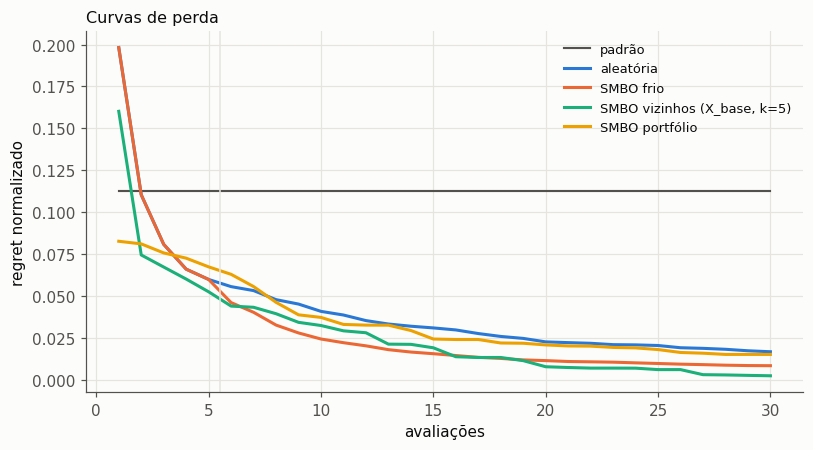

In [10]:
figura, eixo = plt.subplots(figsize=(7.5, 4.2))
cores = [a1.TINTA_2] + a1.SERIES
for (m, v), cor in zip(PRINCIPAIS, cores):
    eixo.plot(range(1, T + 1), por_dataset(m, v).mean(), color=cor, lw=1.4 if m == "padrão" else 2,
              label=f"{m} ({v})" if v else m)
eixo.axvline(N_INIT + 0.5, color=a1.GRADE, lw=1)
eixo.set_xlabel("avaliações")
eixo.set_ylabel("regret normalizado")
eixo.legend(frameon=False, fontsize=8.5)
eixo.set_title("Curvas de perda", loc="left", fontsize=10.5)
figura.tight_layout()
plt.show()

Friedman com 5 avaliações: chi2 = 21.35, p = 0.00027, CD = 1.133


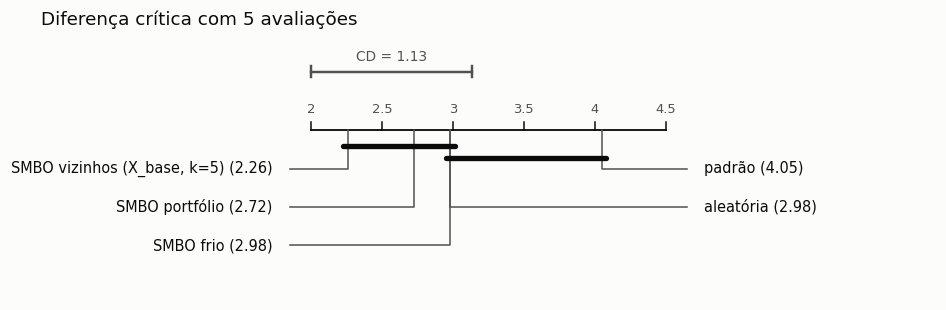

Friedman com 15 avaliações: chi2 = 64.72, p = 2.95e-13, CD = 1.133


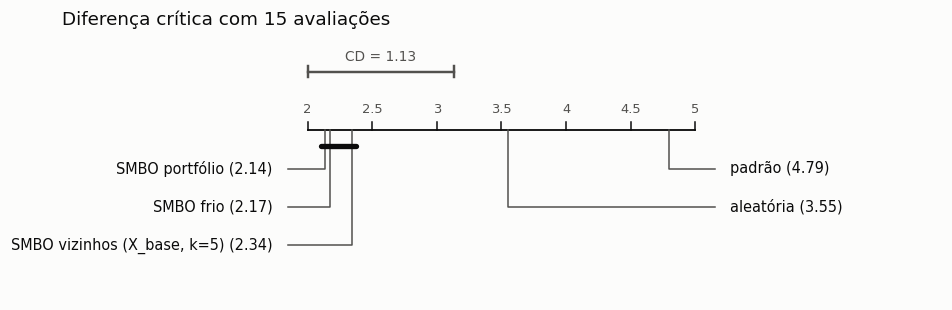

Friedman com 30 avaliações: chi2 = 69.90, p = 2.38e-14, CD = 1.133


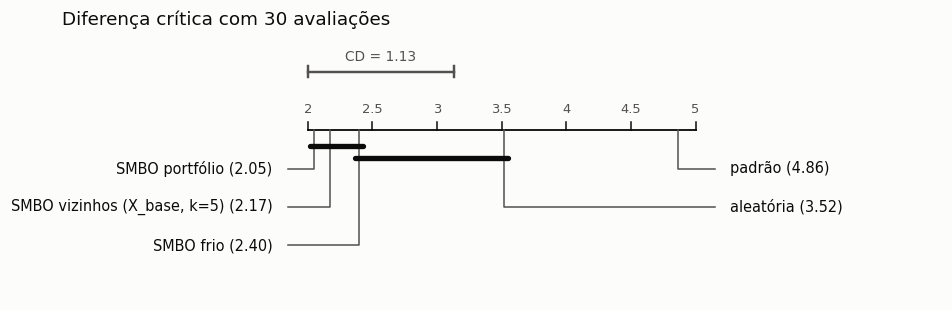

In [11]:
for corte in CORTES:
    valores = np.column_stack([por_dataset(m, v)[corte].to_numpy() for m, v in PRINCIPAIS])
    estatistica, p = stats.friedmanchisquare(*valores.T)
    ranks = pd.Series(np.array([a1._ranquear(linha) for linha in valores]).mean(axis=0),
                      index=[f"{m} ({v})" if v else m for m, v in PRINCIPAIS])
    cd = a1.Q_NEMENYI[len(PRINCIPAIS)] * np.sqrt(len(PRINCIPAIS) * (len(PRINCIPAIS) + 1) / (6 * n))
    print(f"Friedman com {corte} avaliações: chi2 = {estatistica:.2f}, p = {p:.3g}, CD = {cd:.3f}")
    a1.diagrama_dc(ranks, cd, f"Diferença crítica com {corte} avaliações")
    plt.show()

### 3.2 O papel das meta-características

O método 4 com X_base e com X estendido, para k = 1, 3 e 5, contra o portfólio (método 5) e contra um
controle extra: os mesmos k vizinhos, mas sorteados em vez de escolhidos pela distância.

In [12]:
variantes = [("SMBO vizinhos", f"{x}, k={k}") for x in ("X_base", "X estendido") for k in (1, 3, 5)]
variantes += [("SMBO vizinhos aleatórios", f"k={k}") for k in (1, 3, 5)]
variantes += [("SMBO portfólio", ""), ("SMBO frio", "")]

quadro_variantes = pd.DataFrame({
    f"{m} {v}".strip(): {"área": por_dataset(m, v).mean(axis=1).mean(),
                         **{f"regret em {c}": por_dataset(m, v)[c].mean() for c in CORTES}}
    for m, v in variantes}).T


def area(m, v):
    return por_dataset(m, v).mean(axis=1).to_numpy()


def pareado(a, b):
    return 1.0 if np.allclose(a, b) else float(stats.wilcoxon(a, b, zero_method="pratt").pvalue)


comparacoes = [(("SMBO vizinhos", "X_base, k=5"), ("SMBO portfólio", "")),
               (("SMBO vizinhos", "X_base, k=5"), ("SMBO vizinhos", "X estendido, k=5"))]
comparacoes += [(("SMBO vizinhos", f"X_base, k={k}"), ("SMBO vizinhos aleatórios", f"k={k}")) for k in (1, 3, 5)]
quadro_pares = pd.DataFrame([{
    "A": f"{a[0]} {a[1]}".strip(), "B": f"{b[0]} {b[1]}".strip(),
    "A melhor / pior / igual": f"{(area(*a) < area(*b)).sum()} / {(area(*a) > area(*b)).sum()} / {(area(*a) == area(*b)).sum()}",
    "Δ área (A − B)": area(*a).mean() - area(*b).mean(), "p": pareado(area(*a), area(*b))} for a, b in comparacoes])

print("Quadro 6: variantes do warm-start (área e regret médios)")
display(quadro_variantes.round(4))
print("Quadro 7: comparações pareadas da área por dataset (Wilcoxon)")
quadro_pares.round(4)

Quadro 6: variantes do warm-start (área e regret médios)


,área,regret em 5,regret em 15,regret em 30
"SMBO vizinhos X_base, k=1",0.0327,0.0835,0.0143,0.0020
"SMBO vizinhos X_base, k=3",0.0252,0.0482,0.0127,0.0016
"SMBO vizinhos X_base, k=5",0.0278,0.0524,0.0190,0.0023
"SMBO vizinhos X estendido, k=1",0.0390,0.0807,0.0269,0.0165
"SMBO vizinhos X estendido, k=3",0.0340,0.0481,0.0268,0.0174
"SMBO vizinhos X estendido, k=5",0.0255,0.0458,0.0204,0.0008
SMBO vizinhos aleatórios k=1,0.0408,0.0925,0.0232,0.0129
SMBO vizinhos aleatórios k=3,0.0314,0.0593,0.0187,0.0079
SMBO vizinhos aleatórios k=5,0.0291,0.0514,0.0161,0.0070
SMBO portfólio,0.0352,0.0673,0.0242,0.0150


Quadro 7: comparações pareadas da área por dataset (Wilcoxon)


,A,B,A melhor / pior / igual,Δ área (A − B),p
0,"SMBO vizinhos X_base, k=5",SMBO portfólio,11 / 18 / 0,-0.0074,0.7172
1,"SMBO vizinhos X_base, k=5","SMBO vizinhos X estendido, k=5",10 / 19 / 0,0.0024,0.0592
2,"SMBO vizinhos X_base, k=1",SMBO vizinhos aleatórios k=1,18 / 11 / 0,-0.0081,0.4047
3,"SMBO vizinhos X_base, k=3",SMBO vizinhos aleatórios k=3,17 / 12 / 0,-0.0062,0.1207
4,"SMBO vizinhos X_base, k=5",SMBO vizinhos aleatórios k=5,16 / 13 / 0,-0.0013,0.5362


In [13]:
Z = _normalizar(XB, np.arange(n))
distancia = np.abs(Z[:, None, :] - Z[None, :, :]).sum(axis=2)
paisagem = stats.spearmanr(Lm).statistic
pares = np.triu_indices(n, 1)
rho_pares = stats.spearmanr(distancia[pares], paisagem[pares]).statistic

linhas = []
for j in range(n):
    ordem, dist = vizinhos(XB, j)
    outros = np.delete(np.arange(n), j)
    linhas.append({"dataset": NOMES[j], "vizinho em X_base": NOMES[ordem[0]], "distância": dist[0],
                   "correlação com o vizinho": paisagem[j, ordem[0]],
                   "correlação média com os demais": paisagem[j, outros].mean(),
                   "maior correlação possível": paisagem[j, outros].max()})
quadro_paisagem = pd.DataFrame(linhas).set_index("dataset")

print(f"Quadro 8: o vizinho em meta-características tem a paisagem de perdas mais parecida? Correlação de "
      f"Spearman entre as perdas das {K} configurações. Entre todos os pares, ρ(distância, correlação) = {rho_pares:.3f}")
display(quadro_paisagem.mean(numeric_only=True).round(3).to_frame("média"))
quadro_paisagem.sort_values("correlação com o vizinho").round(3)

Quadro 8: o vizinho em meta-características tem a paisagem de perdas mais parecida? Correlação de Spearman entre as perdas das 129 configurações. Entre todos os pares, ρ(distância, correlação) = -0.195


,média
distância,5.244
correlação com o vizinho,0.490
correlação média com os demais,0.356
maior correlação possível,0.811


,vizinho em X_base,distância,correlação com o vizinho,correlação média com os demais,maior correlação possível
dataset,,,,,
MiniBooNE,jannis,4.207,-0.393,0.535,0.971
jannis,jungle_chess_2pcs_raw_endgame_complete,3.991,-0.284,-0.090,0.618
abalone,letter,5.174,-0.249,-0.262,0.637
numerai28.6,MagicTelescope,5.721,-0.142,-0.055,0.436
jm1,sylvine,3.717,0.005,0.029,0.599
waveform-5000,GesturePhaseSegmentationProcessed,2.316,0.142,0.380,0.725
APSFailure,adult,13.674,0.211,0.206,0.471
bank-marketing,electricity,4.384,0.260,0.389,0.902
page-blocks,shuttle,4.304,0.289,-0.085,0.637


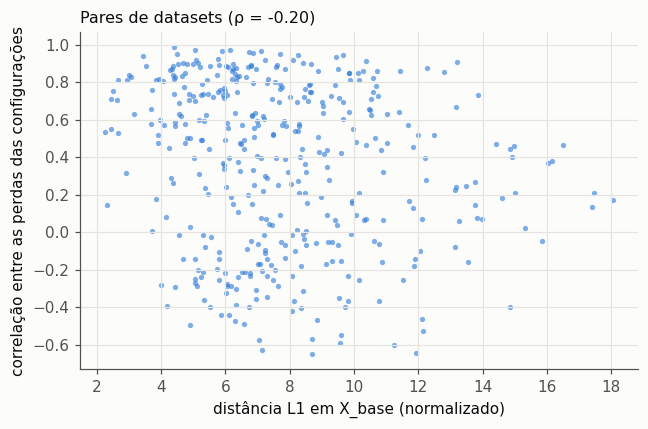

In [14]:
figura, eixo = plt.subplots(figsize=(6, 4))
eixo.scatter(distancia[pares], paisagem[pares], s=12, color=a1.SERIES[0], alpha=0.6, linewidths=0)
eixo.set_xlabel("distância L1 em X_base (normalizado)")
eixo.set_ylabel("correlação entre as perdas das configurações")
eixo.set_title(f"Pares de datasets (ρ = {rho_pares:.2f})", loc="left", fontsize=10.5)
figura.tight_layout()
plt.show()

### 3.3 Quando o warm-start falha

Ganho do método 4 sobre o 3 em cada dataset alvo: área do SMBO frio menos área do SMBO com vizinhos (positivo
é a favor do warm-start), contra a distância ao vizinho mais próximo e contra a correlação entre as perdas do
alvo e as do vizinho.

In [15]:
ganho = pd.Series(area("SMBO frio", "") - area("SMBO vizinhos", "X_base, k=5"), index=NOMES)
ganho_estendido = pd.Series(area("SMBO frio", "") - area("SMBO vizinhos", "X estendido, k=5"), index=NOMES)
rho_dist = stats.spearmanr(ganho, quadro_paisagem["distância"])
rho_corr = stats.spearmanr(ganho, quadro_paisagem["correlação com o vizinho"])

quadro_ganho = pd.DataFrame({
    "ganho": ganho,
    "ganho com X estendido": ganho_estendido,
    "vizinho em X_base": quadro_paisagem["vizinho em X_base"],
    "distância": quadro_paisagem["distância"],
    "correlação com o vizinho": quadro_paisagem["correlação com o vizinho"],
    "regret da melhor do vizinho": por_dataset("SMBO vizinhos", "X_base, k=5")[1],
    "regret em 5, vizinhos": por_dataset("SMBO vizinhos", "X_base, k=5")[N_INIT],
    "regret em 5, frio": por_dataset("SMBO frio", "")[N_INIT],
}).sort_values("ganho")

print(f"Quadro 9: ganho do warm-start por dataset; perde em {(ganho < 0).sum()} de {n}. "
      f"ρ(ganho, distância) = {rho_dist.statistic:.3f} (p = {rho_dist.pvalue:.3f}); "
      f"ρ(ganho, correlação com o vizinho) = {rho_corr.statistic:.3f} (p = {rho_corr.pvalue:.3f})")
quadro_ganho.round(4)

Quadro 9: ganho do warm-start por dataset; perde em 11 de 29. ρ(ganho, distância) = 0.278 (p = 0.144); ρ(ganho, correlação com o vizinho) = 0.501 (p = 0.006)


,ganho,ganho com X estendido,vizinho em X_base,distância,correlação com o vizinho,regret da melhor do vizinho,"regret em 5, vizinhos","regret em 5, frio"
jm1,-0.0444,-0.0217,sylvine,3.7167,0.0050,0.8231,0.1525,0.1455
abalone,-0.0412,-0.0230,letter,5.1738,-0.2487,0.8146,0.0693,0.0352
churn,-0.0215,-0.0142,sylvine,3.1593,0.6311,0.1920,0.1369,0.1279
waveform-5000,-0.0207,-0.0197,GesturePhaseSegmentationProcessed,2.3162,0.1421,0.1893,0.0893,0.0566
jannis,-0.0077,0.0077,jungle_chess_2pcs_raw_endgame_complete,3.9912,-0.2843,0.0819,0.0449,0.0226
MiniBooNE,-0.0056,0.0114,jannis,4.2066,-0.3929,0.2157,0.0364,0.0473
letter,-0.0026,-0.0027,pendigits,2.5722,0.7077,0.0926,0.0002,0.0009
MagicTelescope,-0.0020,0.0056,phoneme,2.9388,0.8096,0.0363,0.0223,0.0199
sylvine,-0.0007,-0.0062,waveform-5000,2.9094,0.3174,0.4161,0.0926,0.1102
page-blocks,-0.0002,0.0006,shuttle,4.3038,0.2892,0.0011,0.0011,0.0011


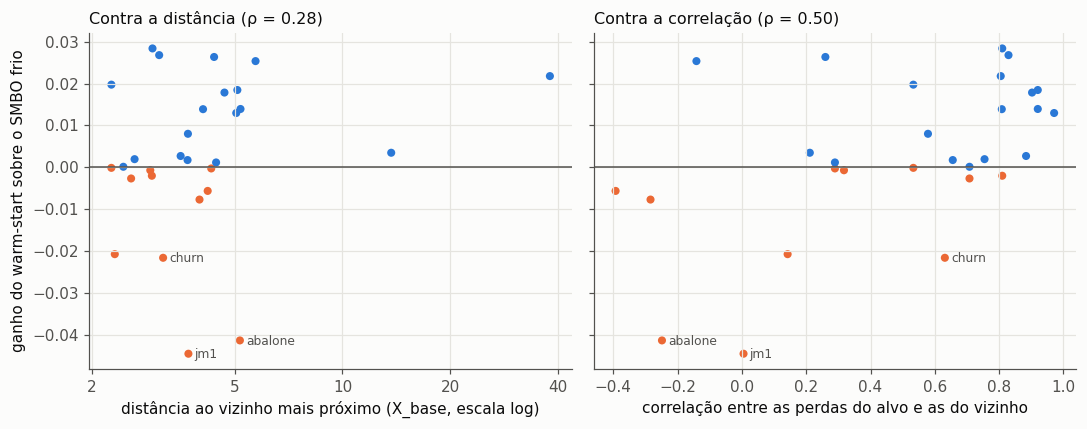

In [16]:
figura, eixos = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
cores_ponto = [a1.SERIES[1] if g < 0 else a1.SERIES[0] for g in quadro_ganho.ganho]
for eixo, coluna, titulo in ((eixos[0], "distância", f"Contra a distância (ρ = {rho_dist.statistic:.2f})"),
                             (eixos[1], "correlação com o vizinho", f"Contra a correlação (ρ = {rho_corr.statistic:.2f})")):
    eixo.scatter(quadro_ganho[coluna], quadro_ganho.ganho, c=cores_ponto, s=28, linewidths=0)
    eixo.axhline(0, color=a1.TINTA_2, lw=1)
    for nome in quadro_ganho.index[:3]:
        eixo.annotate(nome, (quadro_ganho.loc[nome, coluna], quadro_ganho.loc[nome, "ganho"]), fontsize=8,
                      xytext=(4, -3), textcoords="offset points", color=a1.TINTA_2)
    eixo.set_title(titulo, loc="left", fontsize=10.5)
eixos[0].set_xscale("log")
eixos[0].minorticks_off()
eixos[0].set_xticks([2, 5, 10, 20, 40], ["2", "5", "10", "20", "40"])
eixos[0].set_xlabel("distância ao vizinho mais próximo (X_base, escala log)")
eixos[1].set_xlabel("correlação entre as perdas do alvo e as do vizinho")
eixos[0].set_ylabel("ganho do warm-start sobre o SMBO frio")
figura.tight_layout()
plt.show()

## 4. Evidência para a interpretação

O desenho inicial de cada método, o ruído da matriz e o peso de um único dataset na comparação entre vizinhos e
portfólio.

In [17]:
from scipy.spatial.distance import pdist


def desenhos(metodo, variante):
    linhas = buscas[(buscas["método"] == metodo) & (buscas.variante == variante)]
    return linhas[[f"c{i}" for i in range(1, N_INIT + 1)]].to_numpy()


iniciais = [("SMBO frio", ""), ("SMBO vizinhos", "X_base, k=1"), ("SMBO vizinhos", "X_base, k=3"),
            ("SMBO vizinhos", "X_base, k=5"), ("SMBO portfólio", "")]
quadro_desenho = pd.DataFrame({
    f"{m} {v}".strip(): {"distância média entre as 5": np.mean([pdist(U[d]).mean() for d in desenhos(m, v)]),
                         "contém a padrão (%)": 100 * np.mean([0 in d for d in desenhos(m, v)]),
                         "regret da 1ª": por_dataset(m, v)[1].mean(),
                         "regret em 5": por_dataset(m, v)[N_INIT].mean()}
    for m, v in iniciais}).T

print("Quadro 10: as 5 configurações iniciais de cada método (distância euclidiana no cubo unitário, escala log)")
quadro_desenho.round(3)

Quadro 10: as 5 configurações iniciais de cada método (distância euclidiana no cubo unitário, escala log)


,distância média entre as 5,contém a padrão (%),regret da 1ª,regret em 5
SMBO frio,0.804,5.000,0.198,0.060
"SMBO vizinhos X_base, k=1",0.549,6.897,0.160,0.084
"SMBO vizinhos X_base, k=3",0.676,10.345,0.160,0.048
"SMBO vizinhos X_base, k=5",0.690,20.690,0.160,0.052
SMBO portfólio,0.602,58.621,0.083,0.067


In [18]:
from math import comb

auc_folds = folds.pivot_table(index=["nome", "config"], columns="fold", values="auc")
regret_config = (Lm - L_estrela) / escala
limite = stats.t.ppf(0.95, N_FOLDS - 1)

linhas = []
for j, nome in enumerate(NOMES):
    a = auc_folds.loc[nome].to_numpy()
    d = a[Lm[:, j].argmin()] - a
    perto = int((regret_config[:, j] <= 0.01).sum())
    linhas.append({"dataset": nome, "faixa da perda": L_pior[j] - L_estrela[j],
                   "empatadas com a melhor": int((d.mean(axis=1) <= limite * d.std(axis=1, ddof=1) / np.sqrt(N_FOLDS)).sum()),
                   "regret ≤ 0,01": perto,
                   "chance da aleatória achar uma": 1 - comb(K - perto, T) / comb(K, T)})
quadro_ruido = pd.DataFrame(linhas).set_index("dataset").sort_values("empatadas com a melhor", ascending=False)

print(f"Quadro 11: configurações que a matriz não separa da melhor (t pareado nos {N_FOLDS} folds, 5%). "
      f"Mediana de {quadro_ruido['empatadas com a melhor'].median():.0f} das {K} por dataset")
quadro_ruido.round(4)

Quadro 11: configurações que a matriz não separa da melhor (t pareado nos 5 folds, 5%). Mediana de 17 das 129 por dataset


,faixa da perda,empatadas com a melhor,"regret ≤ 0,01",chance da aleatória achar uma
dataset,,,,
wall-robot-navigation,0.0014,125,50,1.0000
APSFailure,0.3551,106,28,0.9998
shuttle,0.3183,87,103,1.0000
numerai28.6,0.0223,66,1,0.2326
page-blocks,0.4722,64,105,1.0000
waveform-5000,0.0102,53,3,0.5512
gas-drift,0.0177,43,65,1.0000
pendigits,0.0704,41,118,1.0000
MagicTelescope,0.0456,40,4,0.6581


In [19]:
contra_portfolio = pd.DataFrame({
    "área, portfólio − vizinhos": area("SMBO portfólio", "") - area("SMBO vizinhos", "X_base, k=5"),
    "regret em 30, portfólio": por_dataset("SMBO portfólio", "")[T].to_numpy(),
    "regret em 30, vizinhos": por_dataset("SMBO vizinhos", "X_base, k=5")[T].to_numpy(),
}, index=NOMES).sort_values("área, portfólio − vizinhos", ascending=False)
maior = contra_portfolio.index[0]
sem = contra_portfolio.drop(index=maior).mean()

print(f"Quadro 12: portfólio contra vizinhos (X_base, k=5). Sem o {maior}, a diferença média de área vai de "
      f"{contra_portfolio.iloc[:, 0].mean():.4f} para {sem.iloc[0]:.4f}, e o regret em 30 fica em "
      f"{sem.iloc[1]:.4f} (portfólio) e {sem.iloc[2]:.4f} (vizinhos)")
contra_portfolio.round(4)

Quadro 12: portfólio contra vizinhos (X_base, k=5). Sem o numerai28.6, a diferença média de área vai de 0.0074 para -0.0004, e o regret em 30 fica em 0.0024 (portfólio) e 0.0024 (vizinhos)


,"área, portfólio − vizinhos","regret em 30, portfólio","regret em 30, vizinhos"
numerai28.6,0.2266,0.3681,0.0000
electricity,0.0330,0.0000,0.0000
connect-4,0.0272,0.0225,0.0000
GesturePhaseSegmentationProcessed,0.0259,0.0000,0.0000
optdigits,0.0241,0.0000,0.0000
phoneme,0.0210,0.0000,0.0000
PhishingWebsites,0.0088,0.0000,0.0000
Bioresponse,0.0070,0.0000,0.0000
nomao,0.0042,0.0000,0.0000
gas-drift,0.0007,0.0000,0.0000
